In [1]:
# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Display / plotting settings
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 150)
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.unicode_minus'] = False

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# 2. Load Dataset
df = pd.read_csv(r"C:\Users\m_hossam\OneDrive\Desktop\data\breast-cancer.csv")
print(f"Dataset loaded: {df.shape[0]:,} rows x {df.shape[1]} columns")

Dataset loaded: 569 rows x 32 columns


In [3]:
df

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,1.1760,1.2560,7.673,158.70,0.010300,0.02891,0.05198,0.02454,0.01114,0.004239,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,0.7655,2.4630,5.203,99.04,0.005769,0.02423,0.03950,0.01678,0.01898,0.002498,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,0.4564,1.0750,3.425,48.55,0.005903,0.03731,0.04730,0.01557,0.01318,0.003892,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,0.7260,1.5950,5.772,86.22,0.006522,0.06158,0.07117,0.01664,0.02324,0.006185,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


| #  | Column                    | الشرح بالعربي                 | المعنى ببساطة                             |
| -- | ------------------------- | ----------------------------- | ----------------------------------------- |
| 1  | `id`                      | رقم تعريف العينة              | رقم مميز لكل حالة                         |
| 2  | `diagnosis`               | التشخيص                       | `M` = خبيث، `B` = حميد                    |
| 3  | `radius_mean`             | متوسط نصف القطر               | متوسط حجم نصف قطر الخلايا/النواة          |
| 4  | `texture_mean`            | متوسط النسيج                  | مقدار اختلاف درجات/شدة البكسلات           |
| 5  | `perimeter_mean`          | متوسط المحيط                  | متوسط طول حدود الخلايا/النواة             |
| 6  | `area_mean`               | متوسط المساحة                 | متوسط مساحة الخلايا/النواة                |
| 7  | `smoothness_mean`         | متوسط النعومة                 | مدى نعومة حدود الشكل                      |
| 8  | `compactness_mean`        | متوسط التماسك                 | مدى قرب الشكل من الشكل المتماسك/الدائري   |
| 9  | `concavity_mean`          | متوسط التقعر                  | مقدار وجود مناطق داخلة للداخل في الحدود   |
| 10 | `concave points_mean`     | متوسط النقاط المقعرة          | مقدار/عدد النقاط التي تحتوي على تقعر      |
| 11 | `symmetry_mean`           | متوسط التماثل                 | مدى تشابه جانبي الشكل                     |
| 12 | `fractal_dimension_mean`  | متوسط التعقيد                 | مقياس لتعقيد وتعرج حدود الشكل             |
| 13 | `radius_se`               | الخطأ المعياري لنصف القطر     | مقدار التغير/عدم اليقين في قياس نصف القطر |
| 14 | `texture_se`              | الخطأ المعياري للنسيج         | مقدار التغير في قياس النسيج               |
| 15 | `perimeter_se`            | الخطأ المعياري للمحيط         | مقدار التغير في قياس المحيط               |
| 16 | `area_se`                 | الخطأ المعياري للمساحة        | مقدار التغير في قياس المساحة              |
| 17 | `smoothness_se`           | الخطأ المعياري للنعومة        | مقدار التغير في قياس النعومة              |
| 18 | `compactness_se`          | الخطأ المعياري للتماسك        | مقدار التغير في قياس التماسك              |
| 19 | `concavity_se`            | الخطأ المعياري للتقعر         | مقدار التغير في قياس التقعر               |
| 20 | `concave points_se`       | الخطأ المعياري للنقاط المقعرة | مقدار التغير في قياس النقاط المقعرة       |
| 21 | `symmetry_se`             | الخطأ المعياري للتماثل        | مقدار التغير في قياس التماثل              |
| 22 | `fractal_dimension_se`    | الخطأ المعياري للتعقيد        | مقدار التغير في قياس تعقيد الحدود         |
| 23 | `radius_worst`            | أسوأ/أكبر قياس لنصف القطر     | أكبر قيمة مسجلة لنصف القطر                |
| 24 | `texture_worst`           | أسوأ/أكبر قياس للنسيج         | أعلى قيمة للنسيج                          |
| 25 | `perimeter_worst`         | أسوأ/أكبر قياس للمحيط         | أكبر قيمة للمحيط                          |
| 26 | `area_worst`              | أسوأ/أكبر قياس للمساحة        | أكبر قيمة للمساحة                         |
| 27 | `smoothness_worst`        | أسوأ قياس للنعومة             | أعلى قيمة مسجلة للنعومة                   |
| 28 | `compactness_worst`       | أسوأ قياس للتماسك             | أعلى قيمة مسجلة للتماسك                   |
| 29 | `concavity_worst`         | أسوأ قياس للتقعر              | أعلى قيمة مسجلة للتقعر                    |
| 30 | `concave points_worst`    | أسوأ قياس للنقاط المقعرة      | أعلى قيمة مسجلة للنقاط المقعرة            |
| 31 | `symmetry_worst`          | أسوأ قياس للتماثل             | أعلى قيمة مسجلة للتماثل                   |
| 32 | `fractal_dimension_worst` | أسوأ قياس للتعقيد             | أعلى قيمة مسجلة لتعقيد الحدود             |


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [5]:
df.isna().sum()

id                         0
diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64

In [6]:
df.describe()


,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,0.405172,1.216853,2.866059,40.337079,0.007041,0.025478,0.031894,0.011796,0.020542,0.003795,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,0.277313,0.551648,2.021855,45.491006,0.003003,0.017908,0.030186,0.006170,0.008266,0.002646,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,0.111500,0.360200,0.757000,6.802000,0.001713,0.002252,0.000000,0.000000,0.007882,0.000895,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,0.232400,0.833900,1.606000,17.850000,0.005169,0.013080,0.015090,0.007638,0.015160,0.002248,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,0.324200,1.108000,2.287000,24.530000,0.006380,0.020450,0.025890,0.010930,0.018730,0.003187,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,0.478900,1.474000,3.357000,45.190000,0.008146,0.032450,0.042050,0.014710,0.023480,0.004558,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,2.873000,4.885000,21.980000,542.200000,0.031130,0.135400,0.396000,0.052790,0.078950,0.029840,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [7]:
df.dtypes

id                           int64
diagnosis                   object
radius_mean                float64
texture_mean               float64
perimeter_mean             float64
area_mean                  float64
smoothness_mean            float64
compactness_mean           float64
concavity_mean             float64
concave points_mean        float64
symmetry_mean              float64
fractal_dimension_mean     float64
radius_se                  float64
texture_se                 float64
perimeter_se               float64
area_se                    float64
smoothness_se              float64
compactness_se             float64
concavity_se               float64
concave points_se          float64
symmetry_se                float64
fractal_dimension_se       float64
radius_worst               float64
texture_worst              float64
perimeter_worst            float64
area_worst                 float64
smoothness_worst           float64
compactness_worst          float64
concavity_worst     

In [8]:
X = df.drop(columns=["id", "diagnosis"])
y = df["diagnosis"]

In [9]:
X

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,1.1760,1.2560,7.673,158.70,0.010300,0.02891,0.05198,0.02454,0.01114,0.004239,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,0.7655,2.4630,5.203,99.04,0.005769,0.02423,0.03950,0.01678,0.01898,0.002498,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,0.4564,1.0750,3.425,48.55,0.005903,0.03731,0.04730,0.01557,0.01318,0.003892,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,0.7260,1.5950,5.772,86.22,0.006522,0.06158,0.07117,0.01664,0.02324,0.006185,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [10]:
y

0      M
1      M
2      M
3      M
4      M
      ..
564    M
565    M
566    M
567    M
568    B
Name: diagnosis, Length: 569, dtype: object

In [11]:
y = y.map({"M": 1, "B": 0})

In [12]:
y

0      1
1      1
2      1
3      1
4      1
      ..
564    1
565    1
566    1
567    1
568    0
Name: diagnosis, Length: 569, dtype: int64

In [13]:
from sklearn.model_selection import train_test_split

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [16]:
X_train_scaled = scaler.fit_transform(X_train)

In [17]:
X_test_scaled = scaler.transform(X_test)

In [18]:
from sklearn.svm import SVC

In [19]:
model = SVC(
    kernel="linear",
    C=1.0,
    random_state=42
)

In [20]:
X_train_scaled
X_test_scaled

array([[-0.77089916, -2.00602473, -0.76451652, ..., -0.38805702,
         0.16254727,  0.06095804],
       [ 1.89472636,  0.96648861,  1.89081582, ...,  1.42292627,
         0.33722232, -0.31041892],
       [ 0.56051506, -0.78108791,  0.57044007, ...,  0.14391558,
         0.38009711,  0.30174696],
       ...,
       [ 0.10179251, -0.01812727,  0.08238707, ..., -0.29280517,
        -0.70288824, -0.52310661],
       [ 0.26682074, -0.63876192,  0.26586259, ...,  0.14541325,
         0.79614133,  0.73153038],
       [ 0.53254417,  0.05420233,  0.48133495, ...,  0.54678897,
        -0.41864428, -1.11598733]], shape=(114, 30))

In [21]:
model.fit(X_train_scaled, y_train)

,C,1.0
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [22]:
y_pred = model.predict(X_test_scaled)

In [23]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-Score :", f1)

Accuracy : 0.9649122807017544
Precision: 1.0
Recall   : 0.9047619047619048
F1-Score : 0.95


In [24]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[72  0]
 [ 4 38]]


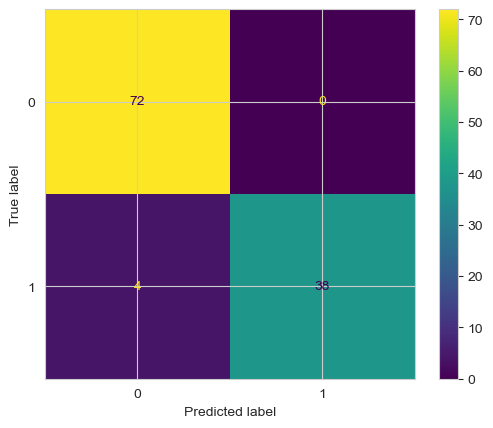

In [25]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.show()

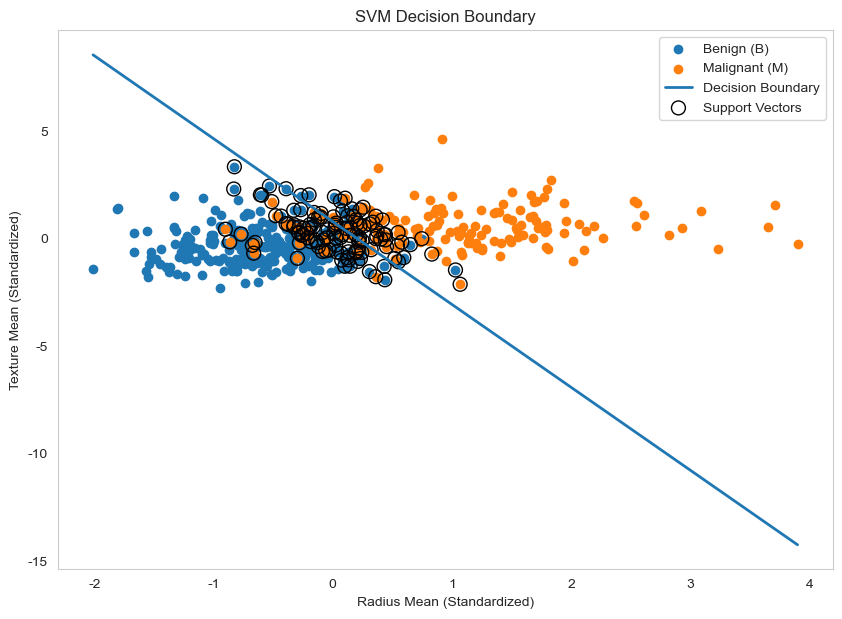

In [26]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Select two features
X_plot = X[["radius_mean", "texture_mean"]]

# Split
X_train_plot, X_test_plot, y_train_plot, y_test_plot = train_test_split(
    X_plot,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Standardization
scaler_plot = StandardScaler()

X_train_plot_scaled = scaler_plot.fit_transform(X_train_plot)

# SVM
svm_plot = SVC(kernel="linear", C=1.0)

svm_plot.fit(X_train_plot_scaled, y_train_plot)

# Plot
plt.figure(figsize=(10, 7))

# Benign
plt.scatter(
    X_train_plot_scaled[y_train_plot == 0, 0],
    X_train_plot_scaled[y_train_plot == 0, 1],
    label="Benign (B)"
)

# Malignant
plt.scatter(
    X_train_plot_scaled[y_train_plot == 1, 0],
    X_train_plot_scaled[y_train_plot == 1, 1],
    label="Malignant (M)"
)

# Decision Boundary
w = svm_plot.coef_[0]
b = svm_plot.intercept_[0]

# Create numeric X values
x_values = np.linspace(
    X_train_plot_scaled[:, 0].min(),
    X_train_plot_scaled[:, 0].max(),
    100
)

# Calculate Y values
y_values = -(w[0] * x_values + b) / w[1]

# Draw Decision Boundary
plt.plot(
    x_values,
    y_values,
    linewidth=2,
    label="Decision Boundary"
)

# Support Vectors
plt.scatter(
    svm_plot.support_vectors_[:, 0],
    svm_plot.support_vectors_[:, 1],
    facecolors="none",
    edgecolors="black",
    s=100,
    label="Support Vectors"
)

plt.xlabel("Radius Mean (Standardized)")
plt.ylabel("Texture Mean (Standardized)")
plt.title("SVM Decision Boundary")

plt.legend()
plt.grid()
plt.show()

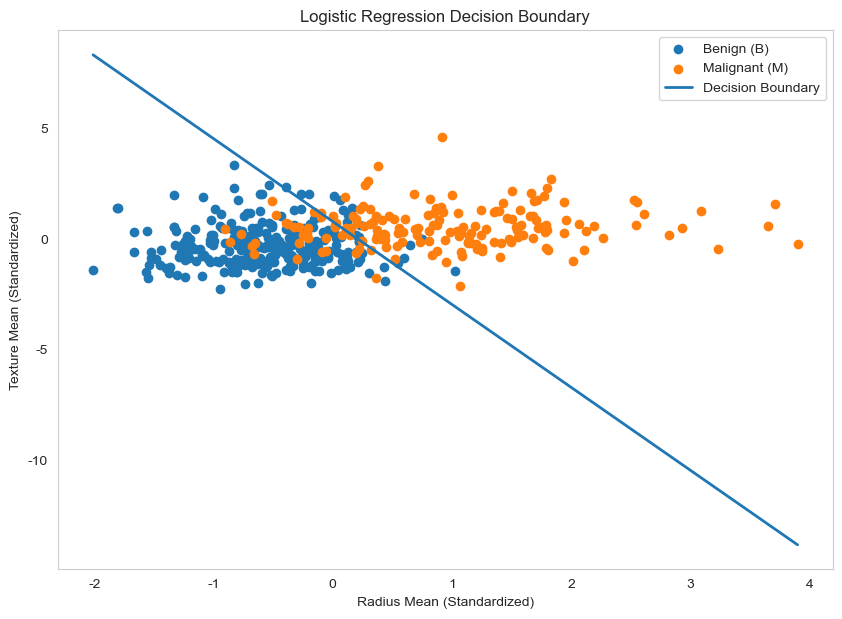

In [27]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# نختار ميزتين فقط للرسم
X_plot = X[["radius_mean", "texture_mean"]]

# تقسيم الداتا
X_train_plot, X_test_plot, y_train_plot, y_test_plot = train_test_split(
    X_plot,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Standardization
scaler_plot = StandardScaler()

X_train_plot_scaled = scaler_plot.fit_transform(X_train_plot)

# Logistic Regression
logistic_plot = LogisticRegression()

logistic_plot.fit(
    X_train_plot_scaled,
    y_train_plot
)

# الرسم
plt.figure(figsize=(10, 7))

# Benign
plt.scatter(
    X_train_plot_scaled[y_train_plot == 0, 0],
    X_train_plot_scaled[y_train_plot == 0, 1],
    label="Benign (B)"
)

# Malignant
plt.scatter(
    X_train_plot_scaled[y_train_plot == 1, 0],
    X_train_plot_scaled[y_train_plot == 1, 1],
    label="Malignant (M)"
)

# معاملات Logistic Regression
w = logistic_plot.coef_[0]
b = logistic_plot.intercept_[0]

# قيم X للرسم
x_values = np.linspace(
    X_train_plot_scaled[:, 0].min(),
    X_train_plot_scaled[:, 0].max(),
    100
)

# Decision Boundary
y_values = -(w[0] * x_values + b) / w[1]

plt.plot(
    x_values,
    y_values,
    linewidth=2,
    label="Decision Boundary"
)

plt.xlabel("Radius Mean (Standardized)")
plt.ylabel("Texture Mean (Standardized)")
plt.title("Logistic Regression Decision Boundary")

plt.legend()
plt.grid()
plt.show()